# 02 — Baselines

**Objectif** : mesurer ce que vaut chaque modalité **seule**, avant toute fusion. Ces chiffres servent de référence : le modèle multimodal final (notebook 05) devra faire mieux.

| ID | Expérience | Question |
|---|---|---|
| E0 | Modèle naïf (hasard stratifié) | Quel est le plancher ? |
| E1a | Clinique seule — régression logistique | Que valent les symptômes, avec un modèle interprétable ? |
| E1b | Clinique seule — gradient boosting | Un modèle non linéaire fait-il mieux ? |
| E2 | Image seule — ViT-B/16 ImageNet gelé + régression logistique | Que vaut l'image avec un encodeur générique ? |

**Protocole (identique pour toutes les expériences)**
- Données : ensemble `train` de `splits.csv` (1 969 images), **5 plis groupés par patient** créés dans le notebook 01.
- L'ensemble `test` n'est **pas utilisé** ici : il est réservé à l'évaluation finale.
- Tout prétraitement (imputation, encodage, standardisation) est appris **dans chaque pli d'entraînement** grâce à un `Pipeline` scikit-learn : aucune information du pli de validation ne fuit.
- Métrique principale : **AUC** (indépendante du seuil). Métriques secondaires au seuil 0,5 : exactitude équilibrée, sensibilité, spécificité, F1.
- Résultat rapporté : moyenne ± écart-type sur les 5 plis.

## 1. Imports et constantes

In [1]:
from pathlib import Path
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (balanced_accuracy_score, f1_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
N_FOLDS = 5

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CSV_PATH = ROOT / "zr7vgbcyr2-1" / "metadata.csv"
SPLITS_PATH = ROOT / "data" / "processed" / "splits.csv"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
REPORT_DIR = ROOT / "outputs" / "reports"
FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# variables retenues dans le notebook 01 (le profil patient est exclu : raccourci)
NUM_COLS = ["age"]
BOOL_COLS = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
CAT_COLS = ["region"]
FEATURES = NUM_COLS + BOOL_COLS + CAT_COLS

## 2. Chargement des données et du découpage

In [2]:
splits = pd.read_csv(SPLITS_PATH)
meta = pd.read_csv(CSV_PATH, na_values=["UNK"])

df = splits.merge(meta[["img_id"] + FEATURES], on="img_id", how="left", validate="one_to_one")
for c in BOOL_COLS:                                   # True / False / NaN -> 1.0 / 0.0 / NaN
    df[c] = df[c].map({True: 1.0, False: 0.0, "True": 1.0, "False": 0.0})

dev = df[df["split"] == "train"].reset_index(drop=True)
X_dev, y_dev, folds = dev[FEATURES], dev["label"].to_numpy(), dev["fold"].to_numpy()

print("Images de développement :", len(dev), "| patients :", dev["patient_id"].nunique())
print("Images par pli :", np.bincount(folds))
print("Manquants dans les variables :", X_dev.isna().sum()[lambda s: s > 0].to_dict())
assert set(folds) == set(range(N_FOLDS))

Images de développement : 1969 | patients : 1176
Images par pli : [394 393 394 394 394]
Manquants dans les variables : {'itch': 4, 'grew': 336, 'hurt': 9, 'changed': 333, 'bleed': 5, 'elevation': 2}


## 3. Fonction d'évaluation commune

`cross_validate` entraîne un modèle neuf sur 4 plis, l'évalue sur le 5ᵉ, et recommence 5 fois. Elle renvoie les métriques par pli et les prédictions « hors pli » (chaque image est prédite par un modèle qui ne l'a jamais vue).

In [3]:
def metrics_at(y_true, proba, threshold=0.5):
    y_pred = (proba >= threshold).astype(int)
    return {
        "AUC": roc_auc_score(y_true, proba),
        "Exactitude équilibrée": balanced_accuracy_score(y_true, y_pred),
        "Sensibilité": recall_score(y_true, y_pred, pos_label=1),
        "Spécificité": recall_score(y_true, y_pred, pos_label=0),
        "F1": f1_score(y_true, y_pred),
    }


def cross_validate(make_model, X, y, folds):
    oof = np.zeros(len(y))
    rows = []
    for k in range(N_FOLDS):
        tr, va = folds != k, folds == k
        model = make_model()
        model.fit(X[tr], y[tr])
        oof[va] = model.predict_proba(X[va])[:, 1]
        rows.append({"pli": k, **metrics_at(y[va], oof[va])})
    return pd.DataFrame(rows), oof


def summarize(name, per_fold):
    m = per_fold.drop(columns="pli")
    return {"Expérience": name, **{c: f"{m[c].mean():.3f} ± {m[c].std():.3f}" for c in m.columns}}


results, oof_preds = [], {}

## 4. E0 — Modèle naïf (plancher)

In [4]:
make_dummy = lambda: DummyClassifier(strategy="stratified", random_state=SEED)
per_fold, oof_preds["E0 Naïf"] = cross_validate(make_dummy, X_dev, y_dev, folds)
results.append(summarize("E0 Naïf", per_fold))
results[-1]

{'Expérience': 'E0 Naïf',
 'AUC': '0.497 ± 0.032',
 'Exactitude équilibrée': '0.497 ± 0.032',
 'Sensibilité': '0.472 ± 0.034',
 'Spécificité': '0.523 ± 0.030',
 'F1': '0.471 ± 0.034'}

## 5. E1 — Clinique seule

Prétraitement appris dans chaque pli :
- `age` : imputation par la médiane puis standardisation ;
- symptômes : imputation par la valeur la plus fréquente ;
- `region` : encodage one-hot (une région absente de l'entraînement est ignorée).

In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), NUM_COLS),
        ("bool", SimpleImputer(strategy="most_frequent"), BOOL_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS),
    ])


def make_logreg():
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=2000))])


def make_hgb():
    return Pipeline([("prep", make_preprocessor()),
                     ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_depth=3,
                                                            learning_rate=0.05, max_iter=300,
                                                            random_state=SEED))])


for name, factory in [("E1a Clinique – logistique", make_logreg),
                      ("E1b Clinique – boosting", make_hgb)]:
    per_fold, oof_preds[name] = cross_validate(factory, X_dev, y_dev, folds)
    results.append(summarize(name, per_fold))
    print(name); print(per_fold.round(3).to_string(index=False)); print()

E1a Clinique – logistique
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.889                  0.814        0.806        0.822 0.804
   1 0.865                  0.780        0.765        0.796 0.769
   2 0.836                  0.750        0.765        0.734 0.743
   3 0.832                  0.736        0.743        0.729 0.728
   4 0.893                  0.834        0.806        0.861 0.822



E1b Clinique – boosting
 pli   AUC  Exactitude équilibrée  Sensibilité  Spécificité    F1
   0 0.902                  0.819        0.812        0.827 0.810
   1 0.847                  0.790        0.754        0.825 0.775
   2 0.854                  0.760        0.791        0.729 0.757
   3 0.838                  0.733        0.717        0.749 0.718
   4 0.898                  0.825        0.823        0.827 0.816



### Interprétation du modèle logistique

Les coefficients indiquent l'effet de chaque variable sur la probabilité de cancer (modèle ajusté sur toutes les données de développement, à titre descriptif uniquement). Un rapport de cotes > 1 augmente le risque.

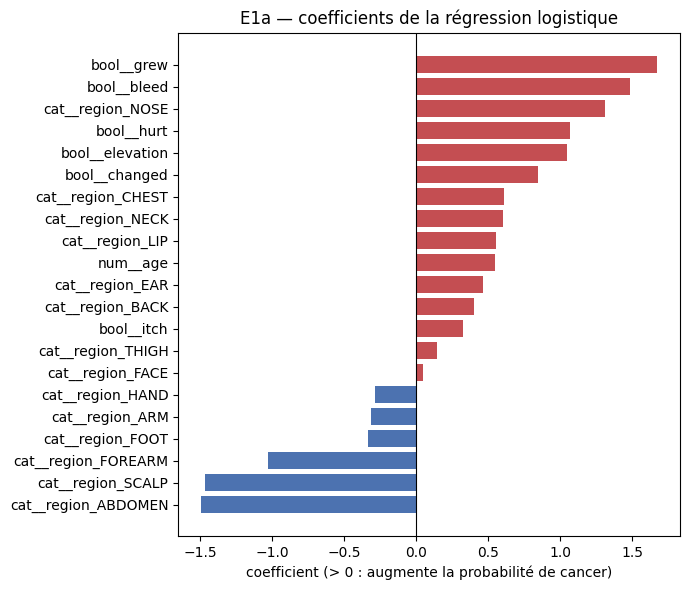

,variable,coefficient,rapport de cotes
17,cat__region_NECK,0.602,1.826
10,cat__region_CHEST,0.607,1.835
4,bool__changed,0.845,2.328
6,bool__elevation,1.044,2.841
3,bool__hurt,1.064,2.897
18,cat__region_NOSE,1.314,3.720
5,bool__bleed,1.485,4.414
2,bool__grew,1.673,5.327


In [6]:
full = make_logreg().fit(X_dev, y_dev)
names = full.named_steps["prep"].get_feature_names_out()
coefs = pd.DataFrame({"variable": names, "coefficient": full.named_steps["clf"].coef_[0]})
coefs["rapport de cotes"] = np.exp(coefs["coefficient"])
coefs = coefs.sort_values("coefficient")

plt.figure(figsize=(7, 6))
plt.barh(coefs["variable"], coefs["coefficient"],
         color=np.where(coefs["coefficient"] > 0, "#C44E52", "#4C72B0"))
plt.axvline(0, color="black", lw=0.8)
plt.title("E1a — coefficients de la régression logistique")
plt.xlabel("coefficient (> 0 : augmente la probabilité de cancer)")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_coefficients_logistique.png", dpi=150)
plt.show()
coefs.round(3).tail(8)

## 6. E2 — Image seule (encodeur ImageNet gelé)

On utilise un **ViT-B/16 préentraîné sur ImageNet**, même architecture que DermLIP-B/16 : la comparaison du notebook 03 sera donc équitable. L'encodeur est **gelé** : on extrait une fois un vecteur de 768 valeurs par image, puis on entraîne une régression logistique (« sonde linéaire ») dans chaque pli.

*L'ajustement fin de l'encodeur demande un GPU ; il sera fait plus tard sur Colab. La sonde linéaire est le protocole standard pour comparer des encodeurs.*

Les caractéristiques sont mises en cache dans `data/processed/` : l'extraction (quelques minutes sur CPU) n'est faite qu'une fois.

> **Attention** : la première exécution de la cellule suivante **télécharge les poids** `vit_b_16-c867db91.pth` (≈ 330 Mo) depuis le site officiel PyTorch (`download.pytorch.org`), puis extrait les caractéristiques des 2 298 images (≈ 5 à 15 min sur CPU). Sur Colab avec GPU, l'extraction prend moins d'une minute.

In [ ]:
import torch
from PIL import Image
from torchvision.models import ViT_B_16_Weights, vit_b_16

FEAT_PATH = PROCESSED_DIR / "features_imagenet_vitb16.npy"
IDS_PATH = PROCESSED_DIR / "features_imagenet_vitb16_ids.csv"

if FEAT_PATH.exists() and IDS_PATH.exists():
    feats = np.load(FEAT_PATH)
    feat_ids = pd.read_csv(IDS_PATH)["img_id"].tolist()
    print("Caractéristiques chargées depuis le cache :", feats.shape)
else:
    torch.manual_seed(SEED)
    torch.set_num_threads(max(1, torch.get_num_threads()))
    weights = ViT_B_16_Weights.IMAGENET1K_V1
    encoder = vit_b_16(weights=weights)
    encoder.heads = torch.nn.Identity()          # on garde le vecteur de 768 valeurs
    encoder.eval()
    preprocess = weights.transforms()            # redimensionnement, recadrage 224, normalisation

    feat_ids = df["img_id"].tolist()
    paths = (ROOT / df["img_path"]).tolist()
    feats, t0 = [], time.time()
    with torch.no_grad():
        for start in range(0, len(paths), 32):
            batch = []
            for p in paths[start:start + 32]:
                with Image.open(p) as im:
                    batch.append(preprocess(im.convert("RGB")))
            feats.append(encoder(torch.stack(batch)).numpy())
            if start % 320 == 0:
                print(f"{start + len(batch)}/{len(paths)} images — {time.time() - t0:.0f} s")
    feats = np.concatenate(feats).astype(np.float32)
    np.save(FEAT_PATH, feats)
    pd.DataFrame({"img_id": feat_ids}).to_csv(IDS_PATH, index=False)
    print("Caractéristiques extraites :", feats.shape, f"en {time.time() - t0:.0f} s")

In [ ]:
index = {img_id: i for i, img_id in enumerate(feat_ids)}
X_img_dev = feats[[index[i] for i in dev["img_id"]]]
assert X_img_dev.shape == (len(dev), 768)


def make_linear_probe():
    return Pipeline([("scale", StandardScaler()),
                     ("clf", LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))])


name = "E2 Image – ViT ImageNet gelé"
per_fold, oof_preds[name] = cross_validate(make_linear_probe, X_img_dev, y_dev, folds)
results.append(summarize(name, per_fold))
print(per_fold.round(3).to_string(index=False))

## 7. Comparaison des baselines

In [ ]:
table = pd.DataFrame(results).set_index("Expérience")
table.to_csv(REPORT_DIR / "02_baselines_resultats.csv")
table

In [ ]:
plt.figure(figsize=(6.5, 6))
for name, proba in oof_preds.items():
    fpr, tpr, _ = roc_curve(y_dev, proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC {roc_auc_score(y_dev, proba):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8)
plt.xlabel("1 − spécificité")
plt.ylabel("Sensibilité")
plt.title("Courbes ROC hors pli (5 plis groupés par patient)")
plt.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.savefig(FIG_DIR / "02_courbes_roc_baselines.png", dpi=150)
plt.show()

## 8. Sauvegarde des prédictions hors pli

In [ ]:
oof = dev[["img_id", "patient_id", "diagnostic", "label", "fold"]].copy()
for name, proba in oof_preds.items():
    oof[name] = proba
oof.to_csv(PROCESSED_DIR / "oof_baselines.csv", index=False)
print("Enregistré :", PROCESSED_DIR / "oof_baselines.csv", oof.shape)

## Conclusion

- **E0 (plancher)** : AUC ≈ 0,50, comme attendu pour un modèle au hasard.
- **E1 (clinique seule)** : AUC ≈ 0,86 (logistique 0,863 ± 0,029 ; boosting 0,868 ± 0,030). Les symptômes, l'âge et la région portent déjà beaucoup d'information. Le boosting n'apporte presque rien face à la logistique : on garde la **logistique**, plus simple et directement interprétable.
- Variables les plus associées au cancer : `grew` (a grossi), `bleed` (saigne), région `NOSE`, `hurt`, `elevation`, `changed`, puis l'âge — cohérent avec la clinique.
- **E2 (image seule, ImageNet)** : *à compléter après exécution de la section 6.*
- Ces valeurs sont les références à battre par DermLIP (notebook 03) puis par le modèle multimodal (notebook 05). L'image devra prouver qu'elle apporte une information **en plus** de la clinique.
- Ces valeurs sont les références à battre par DermLIP (notebook 03) puis par le modèle multimodal (notebook 05).

**Étape suivante** : `03_dermlip.ipynb`.